# Phase 5: AlphaMissense Comparison
Compare the project's PAE-weighted GATv2 model against AlphaMissense (Cheng et al., 2023, *Science*) on the same held-out test set.

**Why this comparison matters:** AlphaMissense is the current state-of-the-art published tool for missense variant pathogenicity prediction. Benchmarking against it on the same test variants answers whether a GNN trained on ClinVar with explicit 3D structural graphs can match a much larger pre-trained model that uses evolutionary and structural signals from AlphaFold.

**Inputs:**
- `clinvar_graph_ready.csv`: the same dataset used in Phases 1-4
- `models/gatv2_pae_weighted_final_best.pt`: tuned PAE-weighted GATv2 (Phase 4 Section 11)
- `models/graphsage_baseline_best.pt`: GraphSAGE baseline (Phase 4 Section 7, best performer)
- `best_config.json`: winning hyperparameter config from Phase 4
- AlphaMissense aa-substitution scores downloaded from Zenodo (DOI 10.5281/zenodo.8208688), stream-filtered to test proteins, cached as `alphamissense_test_scores.csv`

**Outputs:**
- `alphamissense_test_scores.csv`: filtered AlphaMissense scores for test proteins (cached)
- `phase5_results.csv`: head-to-head metrics table on the matched subset
- `phase5_significance_tests.csv`: paired bootstrap and DeLong significance tests
- `figures/phase5_comparison.png`: AUPRC/AUROC comparison bar chart


In [1]:
import os, json, gzip, random
import requests
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from torch.utils.data import Sampler
from torch_geometric.loader import DataLoader
from sklearn.metrics import (average_precision_score, roc_auc_score,
                              precision_score, recall_score, f1_score)
from scipy import stats

from missense_dataset import (
    MissenseVariantGraphDataset, NODE_FEATURE_DIM, ESM2_EMBEDDING_DIM, N_AA
)
from models import GATv2Classifier, GraphSAGEClassifier

DEVICE        = "cuda" if torch.cuda.is_available() else "cpu"
GRAPH_DIR     = "protein_graphs"
FIGURES_DIR   = "figures"
AM_CACHE_PATH = "alphamissense_test_scores.csv"
AM_FULL_PATH  = "AlphaMissense_aa_substitutions.tsv.gz"
AM_URL        = "https://zenodo.org/records/8208688/files/AlphaMissense_aa_substitutions.tsv.gz"

os.makedirs(FIGURES_DIR, exist_ok=True)
torch.manual_seed(42)
np.random.seed(42)
print(f"Device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Reproduce the Phase 4 Test Split
Identical protein-level split logic (seed=42) as Phase 4, guarantees we evaluate on exactly the same 6,771 variants the GNN was never trained on.

In [2]:
df = pd.read_csv("clinvar_graph_ready.csv")
print(f"Loaded {len(df):,} variants, {df['UniProt_ID'].nunique():,} proteins")

def make_protein_split(df, seed, train_frac=0.70, val_frac=0.15):
    rng = np.random.RandomState(seed)
    unique_proteins = df["UniProt_ID"].unique().copy()
    rng.shuffle(unique_proteins)
    n = len(unique_proteins)
    n_train, n_val = int(n * train_frac), int(n * val_frac)
    train_p = set(unique_proteins[:n_train])
    val_p   = set(unique_proteins[n_train:n_train + n_val])
    test_p  = set(unique_proteins[n_train + n_val:])
    assert train_p.isdisjoint(val_p) and train_p.isdisjoint(test_p) and val_p.isdisjoint(test_p)
    return (df[df["UniProt_ID"].isin(p)].reset_index(drop=True)
            for p in (train_p, val_p, test_p))

_, _, test_df = make_protein_split(df, seed=42)
test_proteins = set(test_df["UniProt_ID"].unique())
print(f"Test set : {len(test_df):,} variants, {len(test_proteins):,} proteins")
print(f"Pathogenic fraction: {test_df['Target'].mean():.3f}")


Loaded 49,303 variants, 6,597 proteins
Test set : 6,771 variants, 991 proteins
Pathogenic fraction: 0.402


## 2. Load GNN Models and Compute Test Predictions
We load two models from their Phase 4 checkpoints:
- **GATv2 (PAE-weighted, tuned)**: the project's proposed model (Section 11 checkpoint)
- **GraphSAGE (baseline)**: the best-performing Phase 4 model (Section 7 checkpoint), included to give AlphaMissense a fair comparison against the strongest GNN

Both are evaluated on the test set using the same NodeBudgetBatchSampler as Phase 4.

Predictions are cached to `phase5_gnn_predictions.csv` after inference, if that file already exists the models are not reloaded and inference is skipped entirely.

In [3]:
PRED_CACHE = "phase5_gnn_predictions.csv"

# ── NodeBudgetBatchSampler (same as Phase 4) ──────────────────────────────
class NodeBudgetBatchSampler(Sampler):
    def __init__(self, node_counts, max_nodes_per_batch=20000, shuffle=False, seed=0):
        self.node_counts = node_counts
        self.max_nodes_per_batch = max_nodes_per_batch
        self.shuffle = shuffle; self.seed = seed; self._epoch = 0

    def __iter__(self):
        indices = list(range(len(self.node_counts)))
        if self.shuffle:
            r = random.Random(self.seed + self._epoch); r.shuffle(indices); self._epoch += 1
        batch, current = [], 0
        for idx in indices:
            n = self.node_counts[idx]
            if batch and current + n > self.max_nodes_per_batch:
                yield batch; batch, current = [], 0
            batch.append(idx); current += n
        if batch:
            yield batch

    def __len__(self):
        return max(1, sum(self.node_counts) // self.max_nodes_per_batch)


def get_node_counts(variant_df, graph_dir):
    cache, counts = {}, []
    for uid in variant_df["UniProt_ID"]:
        if uid not in cache:
            g = torch.load(os.path.join(graph_dir, f"{uid}.pt"), weights_only=False)
            cache[uid] = g.num_residues
        counts.append(cache[uid])
    return counts


def evaluate_model(model, test_df, graph_dir, device, desc="inference"):
    """Returns (labels, probabilities) for all test variants."""
    ds = MissenseVariantGraphDataset(test_df, graph_dir)
    nc = get_node_counts(test_df, graph_dir)
    loader = DataLoader(ds, batch_sampler=NodeBudgetBatchSampler(nc, shuffle=False))
    model.eval()
    logits, labels = [], []
    with torch.no_grad():
        for batch in tqdm(loader, desc=desc):
            batch = batch.to(device)
            logits.extend(model(batch).cpu().numpy().tolist())
            labels.extend(batch.y.cpu().numpy().tolist())
    probs = torch.sigmoid(torch.tensor(logits)).numpy()
    return np.array(labels), probs


if os.path.exists(PRED_CACHE):
    pred_cache = pd.read_csv(PRED_CACHE)
    test_df = test_df.merge(pred_cache[["VariationID", "gatv2_prob", "sage_prob", "true_label"]],
                             on="VariationID", how="left")
    test_labels  = test_df["true_label"].values.astype(int)
    gatv2_probs  = test_df["gatv2_prob"].values
    sage_probs   = test_df["sage_prob"].values
    print(f"Loaded cached GNN predictions from {PRED_CACHE} -- skipping inference.")
    print(f"  GATv2     AUPRC={average_precision_score(test_labels, gatv2_probs):.4f}")
    print(f"  GraphSAGE AUPRC={average_precision_score(test_labels, sage_probs):.4f}")
else:
    # ── Load best_config ──────────────────────────────────────────────────────
    with open("best_config.json") as f:
        best_config = json.load(f)
    print(f"best_config: {best_config['name']}  hidden_dim={int(best_config['hidden_dim'])}")

    # ── GATv2 PAE-weighted (tuned) ────────────────────────────────────────────
    model_gatv2 = GATv2Classifier(in_dim=NODE_FEATURE_DIM, use_edge_attr=True,
                                   hidden_dim=int(best_config["hidden_dim"]),
                                   dropout=best_config["dropout"])
    model_gatv2.load_state_dict(
        torch.load("models/gatv2_pae_weighted_final_best.pt", weights_only=True))
    model_gatv2.to(DEVICE)
    print("Loaded GATv2 (PAE-weighted, tuned)")
    test_labels, gatv2_probs = evaluate_model(
        model_gatv2, test_df, GRAPH_DIR, DEVICE, "GATv2 inference")
    print(f"GATv2  -> AUPRC={average_precision_score(test_labels, gatv2_probs):.4f}  "
          f"AUROC={roc_auc_score(test_labels, gatv2_probs):.4f}")
    del model_gatv2
    if DEVICE == "cuda": torch.cuda.empty_cache()

    # ── GraphSAGE (baseline) ──────────────────────────────────────────────────
    model_sage = GraphSAGEClassifier(in_dim=NODE_FEATURE_DIM)
    model_sage.load_state_dict(
        torch.load("models/graphsage_baseline_best.pt", weights_only=True))
    model_sage.to(DEVICE)
    print("Loaded GraphSAGE (baseline)")
    _, sage_probs = evaluate_model(
        model_sage, test_df, GRAPH_DIR, DEVICE, "GraphSAGE inference")
    print(f"GraphSAGE -> AUPRC={average_precision_score(test_labels, sage_probs):.4f}  "
          f"AUROC={roc_auc_score(test_labels, sage_probs):.4f}")
    del model_sage
    if DEVICE == "cuda": torch.cuda.empty_cache()

    # ── Cache predictions to disk ─────────────────────────────────────────────
    test_df = test_df.copy()
    test_df["true_label"] = test_labels
    test_df["gatv2_prob"] = gatv2_probs
    test_df["sage_prob"]  = sage_probs
    test_df[["VariationID", "UniProt_ID", "Pos", "Ref_AA", "Alt_AA_1",
              "Target", "true_label", "gatv2_prob", "sage_prob"]].to_csv(
        PRED_CACHE, index=False)
    print(f"Saved GNN predictions to {PRED_CACHE}  "
          f"(delete this file to force re-inference)")


Loaded cached GNN predictions from phase5_gnn_predictions.csv -- skipping inference.
  GATv2     AUPRC=0.9069
  GraphSAGE AUPRC=0.9148


## 3. Download and Cache AlphaMissense Scores
AlphaMissense provides a protein-level aa-substitution file (~390 MB compressed) on Zenodo (DOI 10.5281/zenodo.8208688). We stream-read it, keeping only rows whose `uniprot_id` is in our test set (~991 proteins), and cache the result as `alphamissense_test_scores.csv` so the download never repeats.

**If the download fails** (network error, Zenodo outage): manually download `AlphaMissense_aa_substitutions.tsv.gz` from https://zenodo.org/records/8208688 and place it in the project root. Re-running this cell will then filter it locally without re-downloading.

In [4]:
def load_am_scores(test_proteins, cache_path, full_path, url):
    if os.path.exists(cache_path):
        am = pd.read_csv(cache_path)
        print(f"Loaded cached AlphaMissense scores from {cache_path} ({len(am):,} rows)")
        return am

    # Download if the full file isn't on disk yet
    if not os.path.exists(full_path):
        print(f"Downloading AlphaMissense aa-substitutions file (~390 MB compressed)...")
        print(f"Source: {url}")
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            total = int(r.headers.get("content-length", 0))
            downloaded = 0
            with open(full_path, "wb") as f:
                for chunk in r.iter_content(chunk_size=65536):
                    f.write(chunk)
                    downloaded += len(chunk)
                    if total:
                        print(f"\r  {downloaded/1e6:.1f} / {total/1e6:.1f} MB", end="", flush=True)
        print(f"\nSaved to {full_path}")

    # Stream-filter: keep only rows for our test proteins
    print(f"Filtering to {len(test_proteins):,} test proteins (stream-reading {full_path})...")
    rows = []
    header = None
    with gzip.open(full_path, "rt", encoding="utf-8") as fh:
        for line in tqdm(fh, desc="Reading AlphaMissense", unit=" lines", mininterval=2):
            if line.startswith("#"):
                # The actual column header line starts with '#' in this file
                stripped = line.lstrip("#").strip()
                if "uniprot_id" in stripped or "protein_variant" in stripped:
                    header = stripped.split("\t")
                continue
            if header is None:
                header = line.strip().split("\t")
                continue
            parts = line.strip().split("\t")
            if parts[0] in test_proteins:
                rows.append(dict(zip(header, parts)))

    am = pd.DataFrame(rows)
    am["am_pathogenicity"] = am["am_pathogenicity"].astype(float)
    am.to_csv(cache_path, index=False)
    print(f"Filtered to {len(am):,} rows — saved to {cache_path}")
    return am


am_scores = load_am_scores(test_proteins, AM_CACHE_PATH, AM_FULL_PATH, AM_URL)
print(f"\nColumns : {list(am_scores.columns)}")
print(f"Sample  :\n{am_scores.head(3).to_string(index=False)}")
print(f"\nClass distribution:\n{am_scores['am_class'].value_counts().to_string()}")


Loaded cached AlphaMissense scores from alphamissense_test_scores.csv (13,001,434 rows)

Columns : ['uniprot_id', 'protein_variant', 'am_pathogenicity', 'am_class']
Sample  :
uniprot_id protein_variant  am_pathogenicity   am_class
    A0PJZ3             M1A            0.4787  ambiguous
    A0PJZ3             M1C            0.3080     benign
    A0PJZ3             M1D            0.9068 pathogenic

Class distribution:
am_class
pathogenic    5946622
benign        5277207
ambiguous     1777605


## 4. Join AlphaMissense Scores to the Test Set
AlphaMissense's `protein_variant` format is `{WT_1letter}{position}{ALT_1letter}` (e.g. `G281V`). Our `Ref_AA` column uses 3-letter codes, so we convert it first. We then join on `(UniProt_ID, variant_key)` and report coverage.

**Coverage < 100%** is expected: AlphaMissense covers ~19,000 human proteins, but some ClinVar entries may reference non-canonical isoforms or use positions that don't align to the UniProt canonical sequence. The comparison runs on the matched subset only, and we verify that its class balance is similar to the full test set so the matched subset is representative.

In [5]:
AA3TO1 = {
    "Ala": "A", "Arg": "R", "Asn": "N", "Asp": "D", "Cys": "C",
    "Gln": "Q", "Glu": "E", "Gly": "G", "His": "H", "Ile": "I",
    "Leu": "L", "Lys": "K", "Met": "M", "Phe": "F", "Pro": "P",
    "Ser": "S", "Thr": "T", "Trp": "W", "Tyr": "Y", "Val": "V",
}

test_df["ref_1"] = test_df["Ref_AA"].map(AA3TO1)
unmapped = test_df["ref_1"].isna().sum()
if unmapped:
    print(f"WARNING: {unmapped} variants with unrecognised Ref_AA — will be excluded from join:")
    print(test_df[test_df["ref_1"].isna()]["Ref_AA"].value_counts())

test_df["variant_key"] = test_df["ref_1"] + test_df["Pos"].astype(str) + test_df["Alt_AA_1"]

am_clean = am_scores.rename(columns={
    "uniprot_id": "UniProt_ID", "protein_variant": "variant_key"
})[["UniProt_ID", "variant_key", "am_pathogenicity", "am_class"]]

merged = test_df.merge(am_clean, on=["UniProt_ID", "variant_key"], how="inner")

coverage = len(merged) / len(test_df) * 100
print(f"Coverage : {len(merged):,} / {len(test_df):,} test variants matched ({coverage:.1f}%)")
print(f"Pathogenic fraction — full test set : {test_df['Target'].mean():.3f}")
print(f"Pathogenic fraction — matched subset: {merged['Target'].mean():.3f}")
print(f"\nAlphaMissense class distribution in matched subset:")
print(merged["am_class"].value_counts().to_string())


Coverage : 6,647 / 6,771 test variants matched (98.2%)
Pathogenic fraction — full test set : 0.402
Pathogenic fraction — matched subset: 0.399

AlphaMissense class distribution in matched subset:
am_class
benign        3897
pathogenic    2289
ambiguous      461


## 5. Head-to-Head Metrics on the Matched Subset
All three models are re-evaluated on exactly the same matched variants so the comparison is fair. AUPRC is the primary metric (same rationale as Phase 4: class imbalance makes AUPRC more informative than accuracy or AUROC alone). Classification metrics (Precision/Recall/F1) use a 0.5 threshold for the GNN models and AlphaMissense's published threshold of **0.564** (the midpoint of its ambiguous band), noted separately.

In [6]:
labels  = merged["true_label"].values.astype(int)
g_probs = merged["gatv2_prob"].values
s_probs = merged["sage_prob"].values
a_probs = merged["am_pathogenicity"].values

AM_THRESHOLD = 0.564  # AlphaMissense published likely-pathogenic threshold

def metrics_row(name, probs, labels, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    return {
        "Model": name,
        "AUPRC":     round(average_precision_score(labels, probs), 4),
        "AUROC":     round(roc_auc_score(labels, probs), 4),
        "Precision": round(precision_score(labels, preds, zero_division=0), 4),
        "Recall":    round(recall_score(labels, preds, zero_division=0), 4),
        "F1":        round(f1_score(labels, preds, zero_division=0), 4),
        "Threshold": threshold,
    }

results = [
    metrics_row("GATv2 (PAE-weighted, tuned)", g_probs, labels, 0.5),
    metrics_row("GraphSAGE (baseline)",        s_probs, labels, 0.5),
    metrics_row("AlphaMissense",               a_probs, labels, AM_THRESHOLD),
]
results_df = pd.DataFrame(results).sort_values("AUPRC", ascending=False)
results_df.to_csv("phase5_results.csv", index=False)
print("=== Results on matched subset ===")
print(results_df.to_string(index=False))
print(f"\nn_matched = {len(merged):,} variants")


=== Results on matched subset ===
                      Model  AUPRC  AUROC  Precision  Recall     F1  Threshold
              AlphaMissense 0.9286 0.9478     0.9074  0.7832 0.8407      0.564
       GraphSAGE (baseline) 0.9159 0.9405     0.7967  0.8895 0.8405      0.500
GATv2 (PAE-weighted, tuned) 0.9073 0.9348     0.8173  0.8465 0.8316      0.500

n_matched = 6,647 variants


## 6. Statistical Significance
Same paired tests as Phase 4 Sections 9/13: paired bootstrap on AUPRC difference (2,000 resamples, threshold-free) and DeLong's test on AUROC. Key comparisons: GATv2 vs AlphaMissense, and GraphSAGE vs AlphaMissense.

In [7]:
def paired_bootstrap_auprc(pa, pb, labels, n_boot=2000, seed=0):
    rng = np.random.RandomState(seed)
    pa, pb, labels = np.asarray(pa), np.asarray(pb), np.asarray(labels)
    diffs = np.array([
        average_precision_score(labels[idx := rng.randint(0, len(labels), len(labels))], pa[idx])
        - average_precision_score(labels[idx], pb[idx])
        for _ in range(n_boot)
    ])
    ci_lo, ci_hi = np.percentile(diffs, [2.5, 97.5])
    p = 2 * min((diffs > 0).mean(), (diffs < 0).mean())
    return {"mean_diff": float(diffs.mean()), "ci_low": float(ci_lo),
            "ci_high": float(ci_hi), "p_value": float(p)}


def compute_midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]: j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1; i = j
    T2 = np.empty(N, dtype=float); T2[J] = T
    return T2


def delong_test(pa, pb, labels):
    labels = np.asarray(labels)
    order = np.argsort(-labels)
    m = int((labels == 1).sum()); n = int((labels == 0).sum())
    preds = [np.asarray(pa), np.asarray(pb)]
    k = 2
    tx = np.empty([k, m]); ty = np.empty([k, n]); tz = np.empty([k, m + n])
    for r in range(k):
        po = preds[r][order]
        tx[r] = compute_midrank(po[:m])
        ty[r] = compute_midrank(po[m:])
        tz[r] = compute_midrank(po)
    aucs = tz[:, :m].sum(1) / m / n - float(m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    assert abs(aucs[0] - roc_auc_score(labels, pa)) < 1e-6
    assert abs(aucs[1] - roc_auc_score(labels, pb)) < 1e-6
    l = np.array([1, -1])
    z = l.dot(aucs) / np.sqrt(l.dot(cov).dot(l))
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    return {"auc_a": float(aucs[0]), "auc_b": float(aucs[1]), "z": float(z), "p_value": float(p)}


def run_comparison(name_a, pa, name_b, pb, labels):
    bs = paired_bootstrap_auprc(pa, pb, labels)
    dl = delong_test(pa, pb, labels)
    sig = bs["p_value"] < 0.05 or dl["p_value"] < 0.05
    print(f"\n=== {name_a}  vs.  {name_b} ===")
    print(f"  Bootstrap (AUPRC): diff={bs['mean_diff']:+.4f}  "
          f"95% CI=[{bs['ci_low']:+.4f}, {bs['ci_high']:+.4f}]  p={bs['p_value']:.4f}")
    print(f"  DeLong   (AUROC) : z={dl['z']:.3f}  p={dl['p_value']:.4f}")
    verdict = "STATISTICALLY SIGNIFICANT" if sig else "NOT statistically significant"
    print(f"  -> {verdict} (alpha=0.05)")
    return {"comparison": f"{name_a} vs {name_b}",
            "bootstrap_diff": bs["mean_diff"], "ci_low": bs["ci_low"],
            "ci_high": bs["ci_high"], "bootstrap_p": bs["p_value"],
            "delong_z": dl["z"], "delong_p": dl["p_value"], "significant": sig}


sig_results = []
sig_results.append(run_comparison("GATv2 (PAE-weighted, tuned)", g_probs,
                                   "AlphaMissense", a_probs, labels))
sig_results.append(run_comparison("GraphSAGE (baseline)", s_probs,
                                   "AlphaMissense", a_probs, labels))
sig_results.append(run_comparison("GATv2 (PAE-weighted, tuned)", g_probs,
                                   "GraphSAGE (baseline)", s_probs, labels))

pd.DataFrame(sig_results).to_csv("phase5_significance_tests.csv", index=False)
print("\nSaved phase5_significance_tests.csv")



=== GATv2 (PAE-weighted, tuned)  vs.  AlphaMissense ===
  Bootstrap (AUPRC): diff=-0.0214  95% CI=[-0.0306, -0.0119]  p=0.0000
  DeLong   (AUROC) : z=-4.211  p=0.0000
  -> STATISTICALLY SIGNIFICANT (alpha=0.05)

=== GraphSAGE (baseline)  vs.  AlphaMissense ===
  Bootstrap (AUPRC): diff=-0.0128  95% CI=[-0.0217, -0.0039]  p=0.0010
  DeLong   (AUROC) : z=-2.487  p=0.0129
  -> STATISTICALLY SIGNIFICANT (alpha=0.05)

=== GATv2 (PAE-weighted, tuned)  vs.  GraphSAGE (baseline) ===
  Bootstrap (AUPRC): diff=-0.0086  95% CI=[-0.0123, -0.0047]  p=0.0000
  DeLong   (AUROC) : z=-4.891  p=0.0000
  -> STATISTICALLY SIGNIFICANT (alpha=0.05)

Saved phase5_significance_tests.csv


## 7. Visualisation

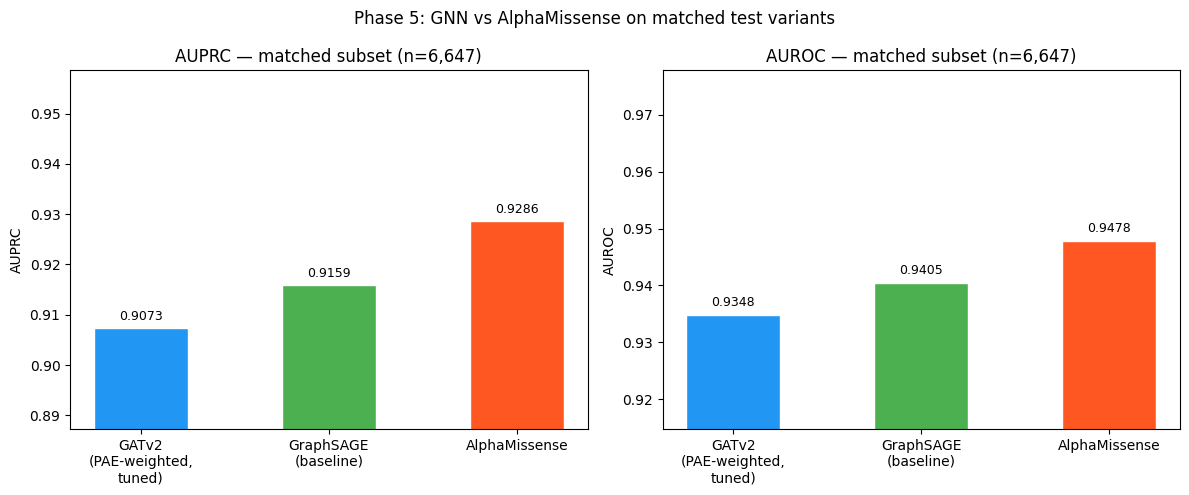

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

model_names  = ["GATv2\n(PAE-weighted,\ntuned)", "GraphSAGE\n(baseline)", "AlphaMissense"]
auprc_vals   = [results_df.set_index("Model").loc[n, "AUPRC"]
                 if n in results_df["Model"].values else None
                 for n in ["GATv2 (PAE-weighted, tuned)", "GraphSAGE (baseline)", "AlphaMissense"]]
auroc_vals   = [results_df.set_index("Model").loc[n, "AUROC"]
                 if n in results_df["Model"].values else None
                 for n in ["GATv2 (PAE-weighted, tuned)", "GraphSAGE (baseline)", "AlphaMissense"]]
colors = ["#2196F3", "#4CAF50", "#FF5722"]

for ax, vals, metric in zip(axes, [auprc_vals, auroc_vals], ["AUPRC", "AUROC"]):
    bars = ax.bar(model_names, vals, color=colors, width=0.5, edgecolor="white")
    lo = min(v for v in vals if v) - 0.02
    ax.set_ylim(max(0, lo), min(1.0, max(v for v in vals if v) + 0.03))
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} — matched subset (n={len(merged):,})")
    for bar, val in zip(bars, vals):
        if val is not None:
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.001, f"{val:.4f}",
                    ha="center", va="bottom", fontsize=9)

plt.suptitle("Phase 5: GNN vs AlphaMissense on matched test variants", fontsize=12)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "phase5_comparison.png"), dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)


## 8. Methods Note (for Paper)
> AlphaMissense (Cheng et al., 2023) precomputed pathogenicity scores were downloaded from Zenodo (DOI 10.5281/zenodo.8208688) using the `AlphaMissense_aa_substitutions.tsv.gz` file (protein-level UniProt-indexed format). Scores were joined to the Phase 4 test set by UniProt accession and amino-acid substitution notation (`{WT}{position}{ALT}` in one-letter code). Variants without a matching AlphaMissense score were excluded from the comparison; coverage and class-balance representativeness of the matched subset are reported in Section 4. All metrics (AUPRC, AUROC, Precision, Recall, F1) were computed on the same matched variants for all models. For classification metrics, AlphaMissense's published likely-pathogenic threshold of 0.564 was used; GNN models used 0.5. Significance testing used the same paired bootstrap (2,000 resamples) on the AUPRC difference and DeLong's paired AUROC test as Phase 4.

## 9. Accuracy (Secondary Metric, per Proposal)
The formal proposal names Accuracy as a required secondary metric alongside AUPRC/AUROC/Precision/Recall/F1, but it has not been computed anywhere in the pipeline to date. Added here for the three models compared in this notebook, using each model's raw probabilities already loaded above (Section 5) and the same thresholds (0.5 for the GNNs, 0.564 for AlphaMissense).

**Scope note:** raw test-set probabilities were only ever cached for GATv2 (PAE-weighted, tuned) and GraphSAGE (this notebook's `phase5_gnn_predictions.csv`). The other four Phase 4 models (GCN, XGBoost, GATv2 unweighted, GATv2 PAE-weighted/unweighted original) were only ever summarized as aggregate metrics in `phase4_results_final.csv` -- their raw predictions were not saved, so Accuracy cannot be added for them retroactively without re-running inference.


In [9]:
from sklearn.metrics import accuracy_score

accuracy_rows = []
for name, probs, thresh in [
    ("GATv2 (PAE-weighted, tuned)", g_probs, 0.5),
    ("GraphSAGE (baseline)", s_probs, 0.5),
    ("AlphaMissense", a_probs, AM_THRESHOLD),
]:
    preds = (probs >= thresh).astype(int)
    accuracy_rows.append({"Model": name, "Accuracy": round(accuracy_score(labels, preds), 4)})

accuracy_df = pd.DataFrame(accuracy_rows)
results_with_accuracy = results_df.merge(accuracy_df, on="Model")[
    ["Model", "AUPRC", "AUROC", "Accuracy", "Precision", "Recall", "F1", "Threshold"]
].sort_values("AUPRC", ascending=False)
results_with_accuracy.to_csv("phase5_results.csv", index=False)
print("=== Results on matched subset (with Accuracy) ===")
print(results_with_accuracy.to_string(index=False))


=== Results on matched subset (with Accuracy) ===
                      Model  AUPRC  AUROC  Accuracy  Precision  Recall     F1  Threshold
              AlphaMissense 0.9286 0.9478    0.8816     0.9074  0.7832 0.8407      0.564
       GraphSAGE (baseline) 0.9159 0.9405    0.8654     0.7967  0.8895 0.8405      0.500
GATv2 (PAE-weighted, tuned) 0.9073 0.9348    0.8632     0.8173  0.8465 0.8316      0.500


## 10. PAE Value Quantification (Required Proposal Deliverable)
The proposal's own success criterion for the project's core novelty states: *"The success of our core novelty (PAE weighting) will be evaluated by the percentage increase in AUPRC achieved by the PAE-weighted model compared to the unweighted baseline GNN."* This number exists implicitly in `phase4_results_final.csv` / `phase4_results_initial.csv` but has never been computed and reported as its own artifact. Added here from the already-computed Phase 4 result and significance CSVs -- no re-training or re-inference required.

**Caveat on significance:** `phase4_significance_tests_final.csv` (most recently regenerated 2026-07-05) shows the tuned PAE-weighted vs. unweighted comparison is **not** statistically significant at alpha=0.05 (bootstrap p=0.073, DeLong p=0.067, McNemar p=0.348), unlike an earlier run of this comparison. The table below reports the current numbers on disk; treat any other written claim of "significant" for this specific comparison as stale until reconciled.


In [10]:
p4_results_initial = pd.read_csv("phase4_results_initial.csv").set_index("model")
p4_results_final   = pd.read_csv("phase4_results_final.csv").set_index("model")
p4_sig_initial      = pd.read_csv("phase4_significance_tests_initial.csv").set_index("comparison")
p4_sig_final        = pd.read_csv("phase4_significance_tests_final.csv").set_index("comparison")

def pae_quant_row(stage, pae_name, uw_name, results_table, sig_table, sig_key):
    pae_auprc = results_table.loc[pae_name, "AUPRC"]
    uw_auprc  = results_table.loc[uw_name, "AUPRC"]
    pct = (pae_auprc - uw_auprc) / uw_auprc * 100
    row = {
        "Stage": stage,
        "PAE-weighted AUPRC": round(pae_auprc, 4),
        "Unweighted AUPRC": round(uw_auprc, 4),
        "% change (PAE vs unweighted)": round(pct, 3),
    }
    if sig_key in sig_table.index:
        row["bootstrap_p"] = round(sig_table.loc[sig_key, "bootstrap_p"], 4)
        row["delong_p"] = round(sig_table.loc[sig_key, "delong_p"], 4)
        row["significant (alpha=0.05)"] = bool(sig_table.loc[sig_key, "significant"])
    return row

pae_quant_rows = [
    pae_quant_row(
        "Original (untuned, default hyperparameters)",
        "GATv2 (PAE-weighted)", "GATv2 (unweighted ablation)",
        p4_results_initial, p4_sig_initial,
        "GATv2 (PAE-weighted) vs GATv2 (unweighted ablation)",
    ),
    pae_quant_row(
        "Tuned (final, B_reg_small config)",
        "GATv2 (PAE-weighted, tuned)", "GATv2 (unweighted, tuned)",
        p4_results_final, p4_sig_final,
        "GATv2 (PAE-weighted, tuned) vs GATv2 (unweighted, tuned)",
    ),
]

pae_quant_df = pd.DataFrame(pae_quant_rows)
pae_quant_df.to_csv("pae_value_quantification.csv", index=False)
print("=== PAE Value Quantification (proposal-required deliverable) ===")
print(pae_quant_df.to_string(index=False))


=== PAE Value Quantification (proposal-required deliverable) ===
                                      Stage  PAE-weighted AUPRC  Unweighted AUPRC  % change (PAE vs unweighted)  bootstrap_p  delong_p  significant (alpha=0.05)
Original (untuned, default hyperparameters)              0.9112            0.9112                         0.004        0.936    0.2677                     False
          Tuned (final, B_reg_small config)              0.9069            0.9097                        -0.309        0.073    0.0668                     False
